In [ ]:
"""
Build Your First Neural Network — Build a small ANN in Keras with this exact architecture: Dense(16, activation="relu") → Dense(8, activation="relu") → Dense(1, activation="sigmoid").
Compile it with the Adam optimizer and binary_crossentropy loss, split the data into train/test, train for about 30 epochs, and report test accuracy.
Plot the training vs. validation loss curve. In 2–3 sentences, explain in your own words what forward propagation and backpropagation are doing each epoch as the model trains.
"""

In [28]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [30]:
import tensorflow as tf
from tensorflow import keras

In [31]:
from keras.layers import Input,Dense,Dropout
from keras.models import Sequential
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

In [32]:
df = pd.read_csv("/content/glass.csv")

In [33]:
df

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


In [34]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [35]:
df['Type'].value_counts()

,count
Type,
2,76
1,70
7,29
3,17
5,13
6,9


In [36]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


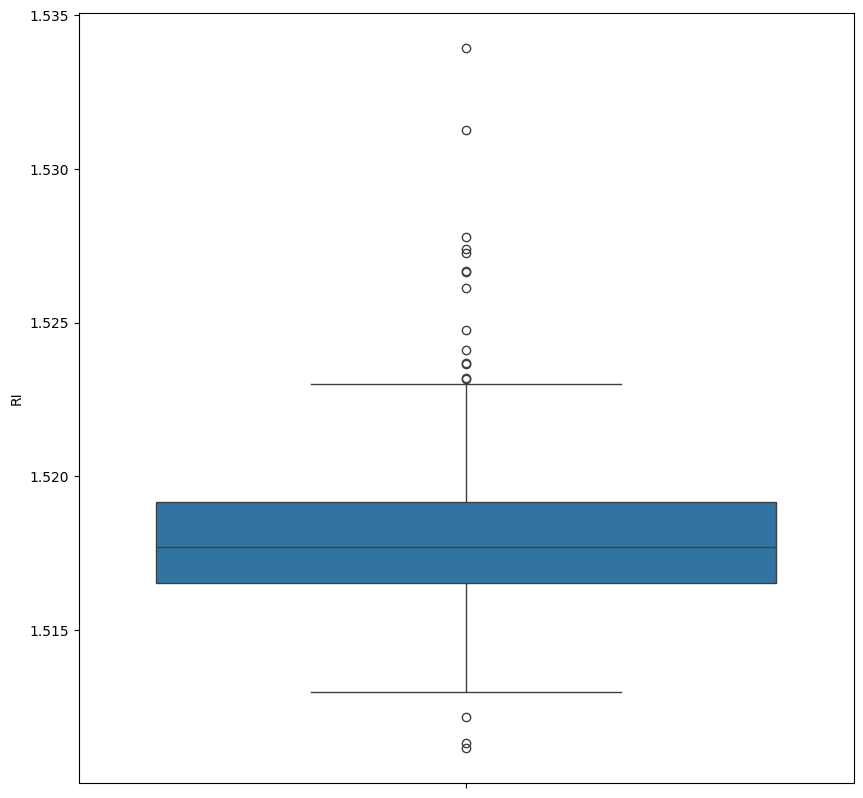

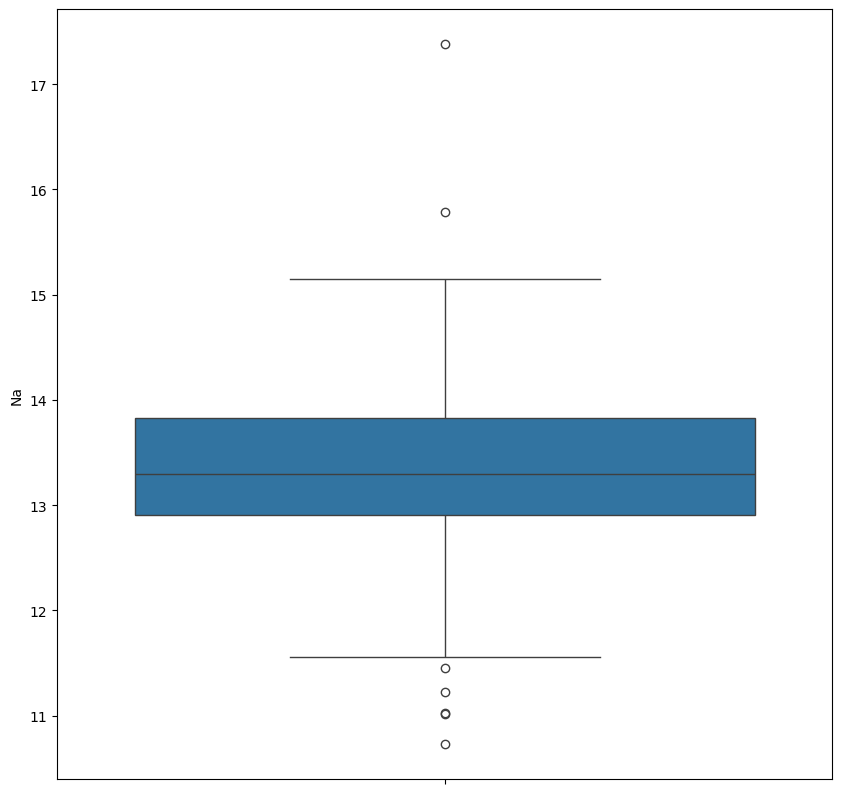

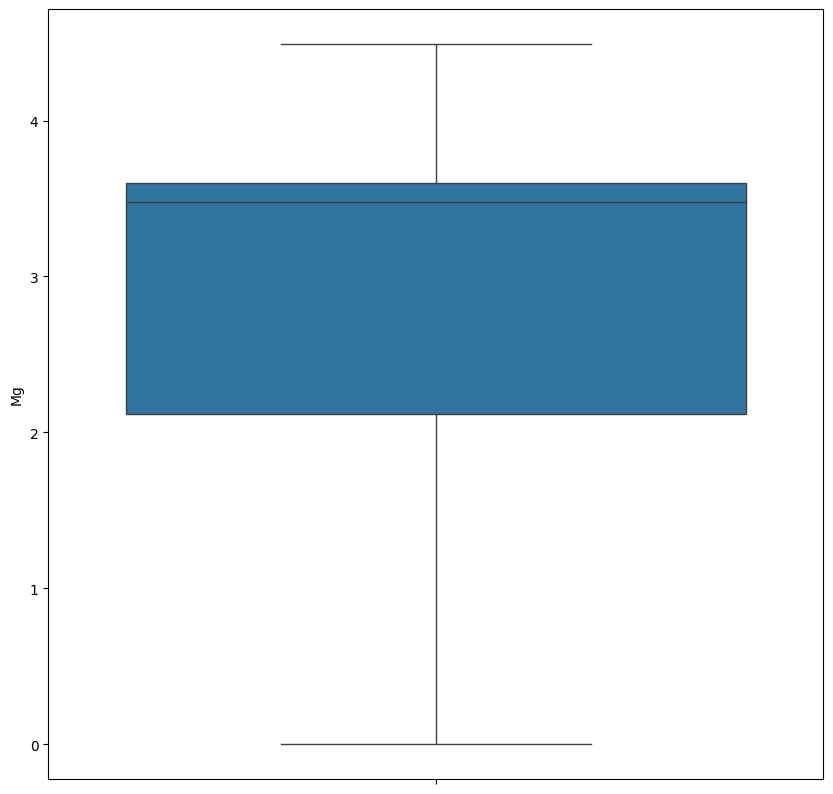

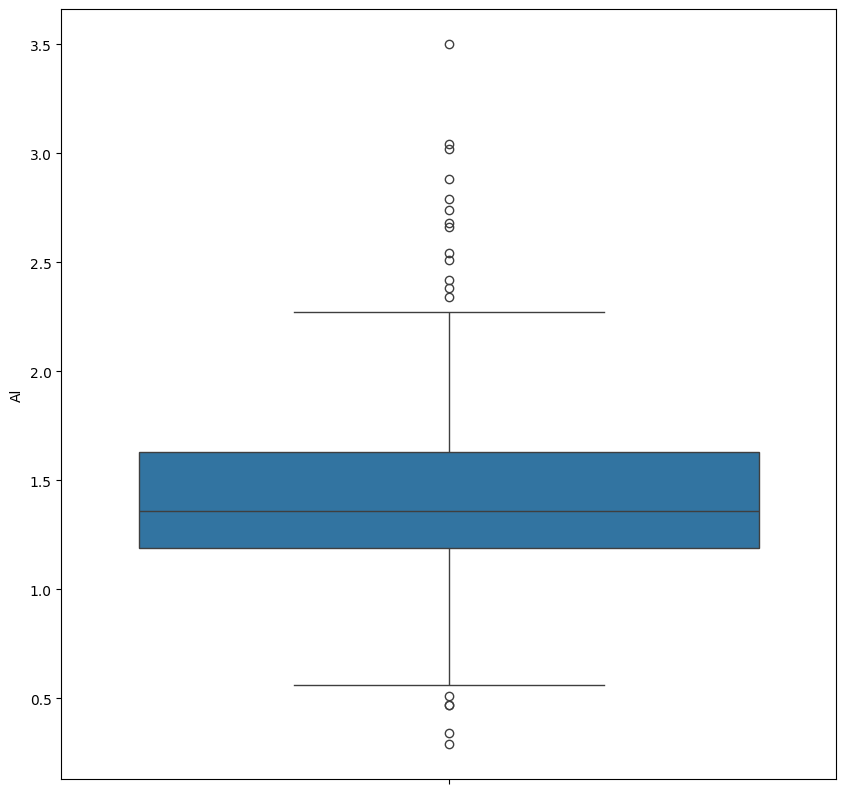

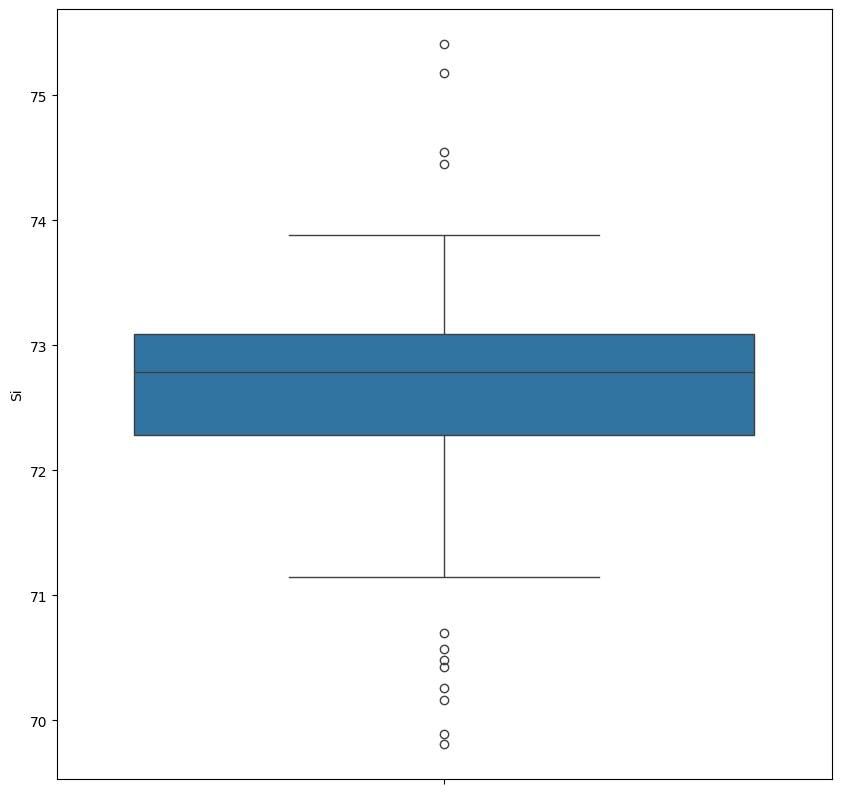

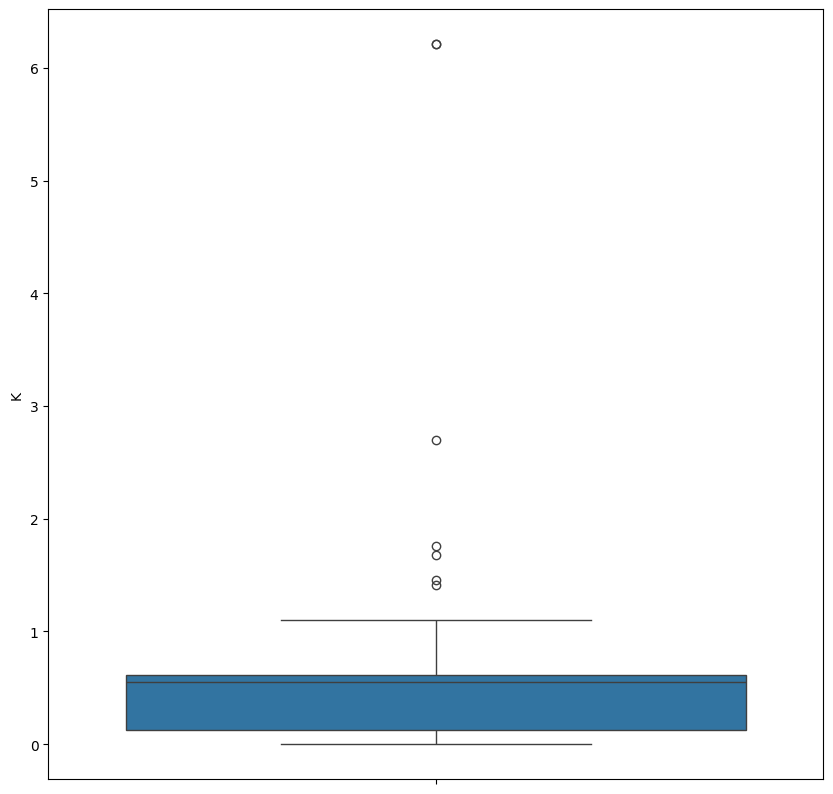

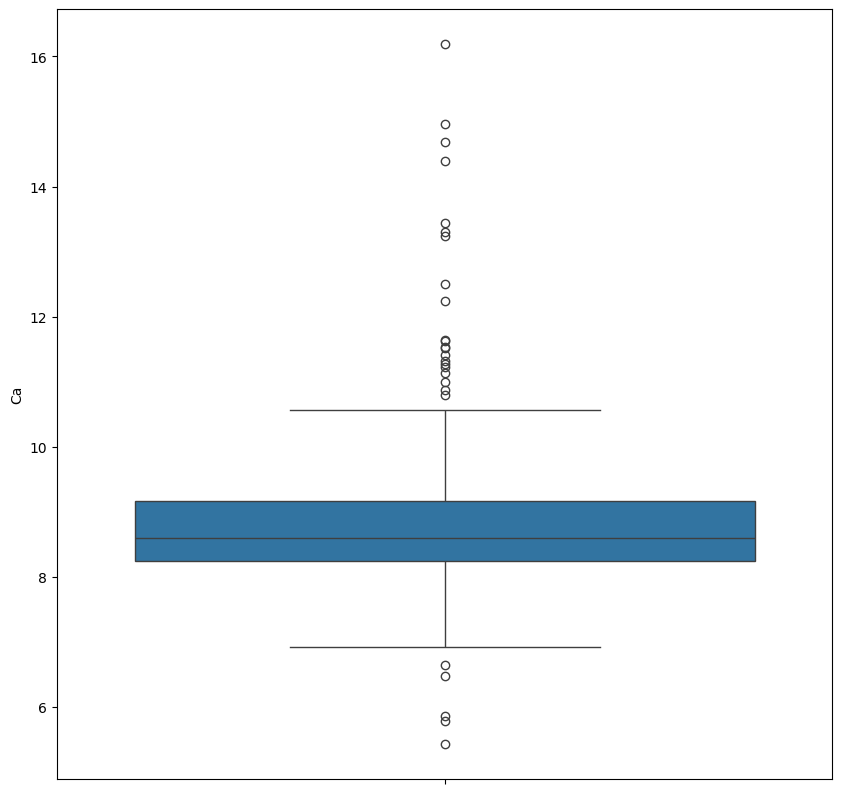

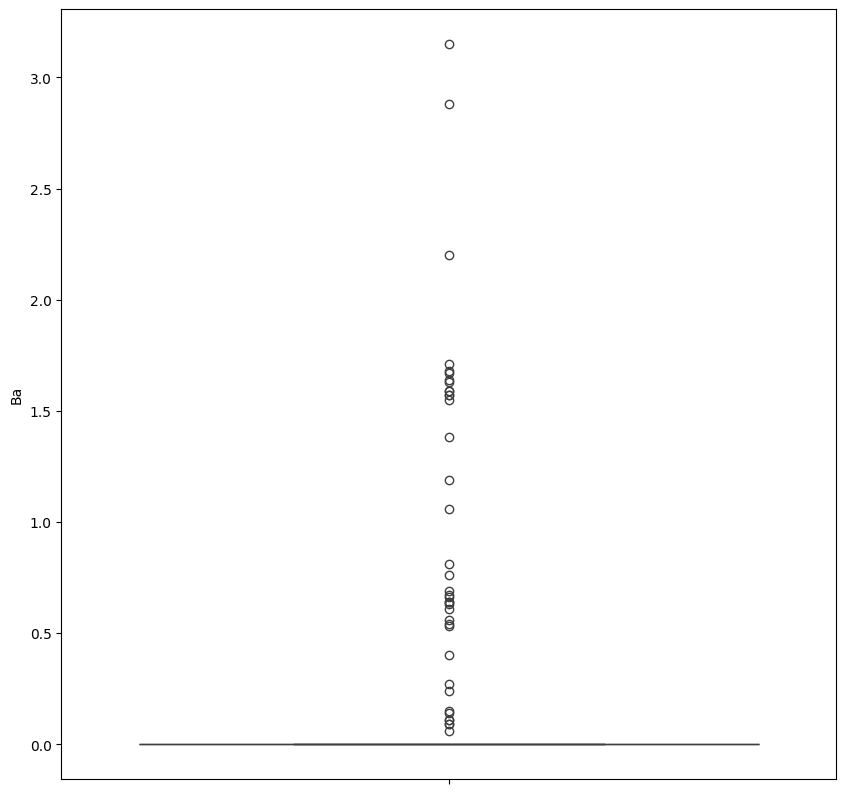

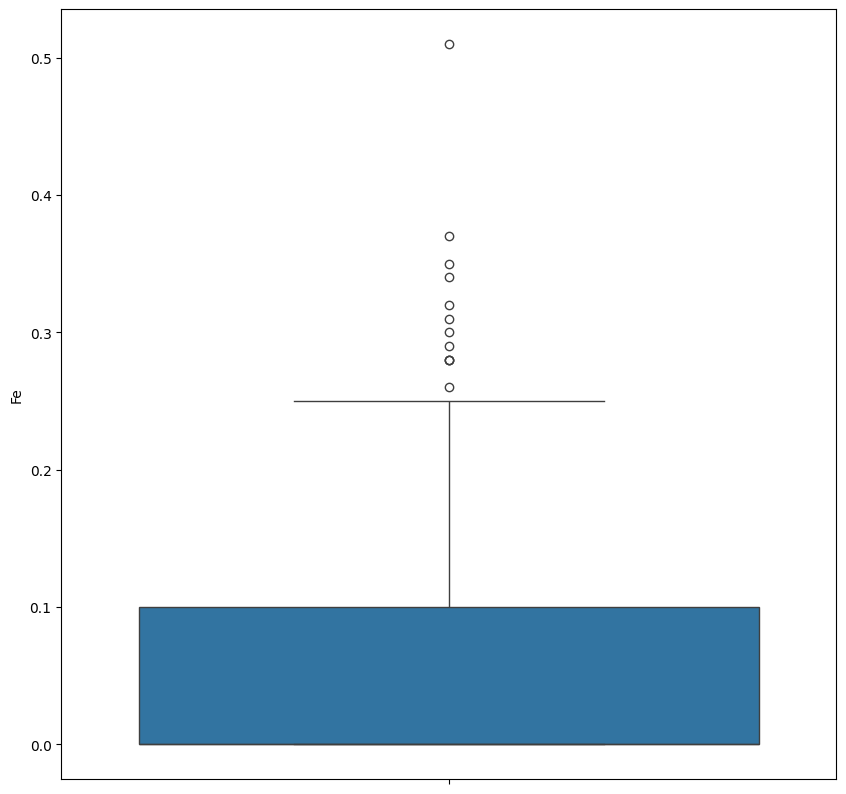

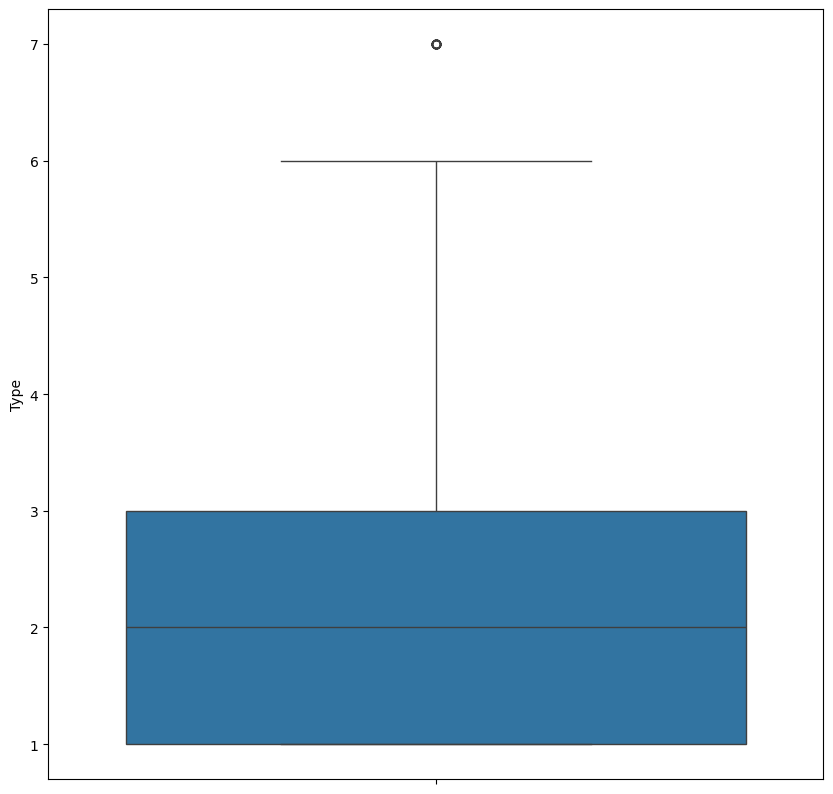

In [37]:
for i in df.columns:
  plt.figure(figsize=(10,10))
  sns.boxplot(df[i])
  plt.show()

In [18]:
df.duplicated().sum()

np.int64(0)

In [17]:
df = df.drop_duplicates()

In [38]:
X = df.drop('Type', axis= 1)
Y = df['Type']

In [44]:
X

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0
...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0


In [45]:
np.unique(Y)

array([1, 2, 3, 5, 6, 7])

In [63]:
class_map = {1: 0, 2: 1, 3: 2, 5: 3, 6: 4, 7: 5}

Y = Y.map(class_map)

In [64]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,random_state=42,test_size=0.2,stratify=Y)

In [65]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5])

In [66]:
x_train.shape

(171, 9)

### 1. Scaling the Features
We will scale our training and testing features using `StandardScaler` so that all input variables have a mean of 0 and a standard deviation of 1.

In [72]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

### 2. Rebuilding the Model with Standardized Data and Optimized Learning Rate

In [73]:
# Rebuild model
model_scaled = Sequential([
    Input(shape=(9,)),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dropout(0.25),
    Dense(6, activation='softmax')
])

# Compile with a lower learning rate for stable convergence
model_scaled.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=Adam(learning_rate=0.003),
    metrics=['accuracy']
)

# Fit the model on scaled features
history_scaled = model_scaled.fit(
    x_train_scaled,
    y_train,
    epochs=40,
    validation_split=0.2,
    verbose=1
)

Epoch 1/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.4118 - loss: 1.6404 - val_accuracy: 0.5143 - val_loss: 1.4804
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6103 - loss: 1.2510 - val_accuracy: 0.4857 - val_loss: 1.3993
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6544 - loss: 1.0477 - val_accuracy: 0.5143 - val_loss: 1.4002
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6397 - loss: 0.9015 - val_accuracy: 0.5143 - val_loss: 1.4125
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6838 - loss: 0.8111 - val_accuracy: 0.4571 - val_loss: 1.3903
Epoch 6/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6912 - loss: 0.7448 - val_accuracy: 0.4571 - val_loss: 1.3844
Epoch 7/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7500 - loss: 0.7037 - val_accuracy: 0.4571 - val_loss: 1.3744
Epoch 8/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7868 - loss: 0.6191 - val_accuracy: 0.5143 - val_loss: 1.2870


### 3. Evaluate on the Test Set & Plot Performance

Scaled Model Test Accuracy: 0.7674


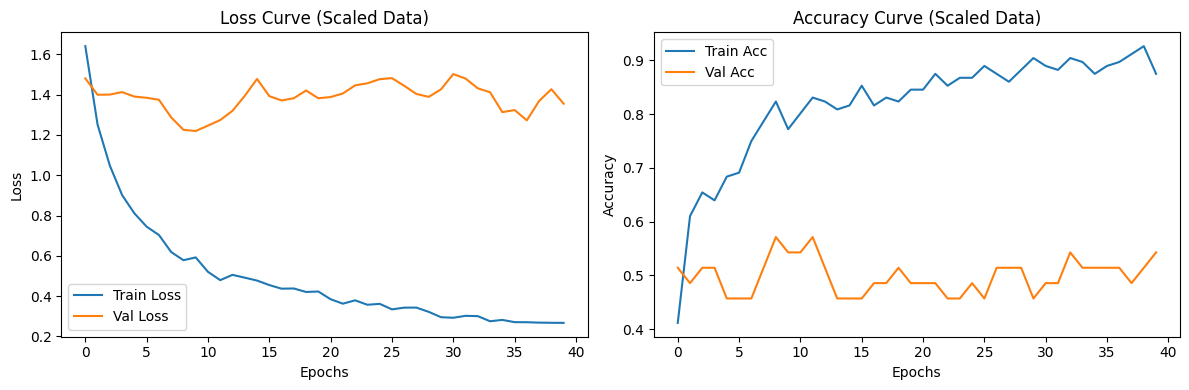

In [74]:
# Evaluate
test_loss, test_acc = model_scaled.evaluate(x_test_scaled, y_test, verbose=0)
print(f"Scaled Model Test Accuracy: {test_acc:.4f}")

# Plot the curves
plt.figure(figsize=(12, 4))

# Loss Curve
plt.subplot(1, 2, 1)
plt.plot(history_scaled.history['loss'], label='Train Loss')
plt.plot(history_scaled.history['val_loss'], label='Val Loss')
plt.title('Loss Curve (Scaled Data)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(history_scaled.history['accuracy'], label='Train Acc')
plt.plot(history_scaled.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy Curve (Scaled Data)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

### Training vs. Validation Loss Curve
Let's plot the loss curves for the trained model to visualize optimization progress over 40 epochs.

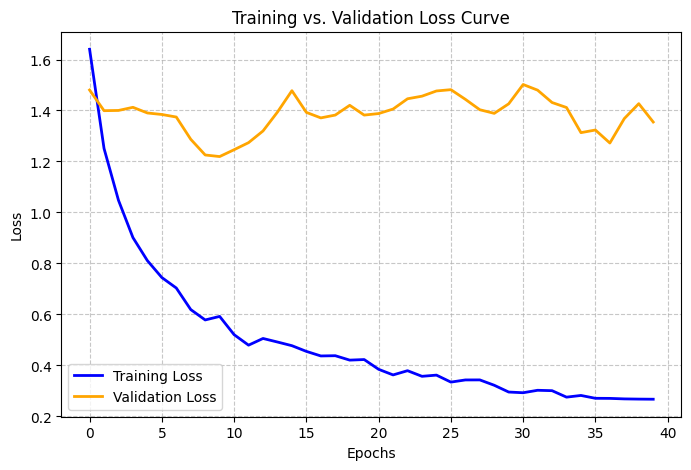

In [75]:
plt.figure(figsize=(8, 5))
plt.plot(history_scaled.history['loss'], label='Training Loss', color='blue', lw=2)
plt.plot(history_scaled.history['val_loss'], label='Validation Loss', color='orange', lw=2)
plt.title('Training vs. Validation Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Explanation of Forward and Backpropagation
During each epoch, **forward propagation** feeds the input features through the network's layers, multiplying them by weights and applying activation functions, to calculate a prediction and measure its error against the actual target. In response, **backpropagation** computes the gradient of this loss with respect to every weight and bias using the mathematical chain rule, sending the error signal backward so the optimizer can adjust the parameters and reduce prediction error in subsequent rounds.